<a href="https://colab.research.google.com/github/arulesharulesh/sentemantalanalysis/blob/main/restaurant_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install pandas numpy scikit-learn matplotlib seaborn tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 799.7 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 80.9 MB/s eta 0:00:00


In [ ]:
from google.colab import files
import os

print("Click below to upload your dataset file:")
uploaded = files.upload()

for fn in uploaded.keys():
  print(f'Successfully uploaded "{fn}" ({len(uploaded[fn])} bytes)')

Click below to upload your dataset file:


Saving Restaurant_Reviews.tsv to Restaurant_Reviews.tsv
Successfully uploaded "Restaurant_Reviews.tsv" (62347 bytes)


In [ ]:
import pandas as pd

# Load the uploaded TSV file using tab delimiter
df = pd.read_csv('Restaurant_Reviews.tsv', sep='\t')

# Display basic information and the first few rows
print("Dataset Shape:", df.shape)
print("\nDataset Info:")
print(df.info())
print("\nFirst 5 rows:")
df.head()

Dataset Shape: (1000, 2)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Review  1000 non-null   object
 1   Liked   1000 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 15.8+ KB
None

First 5 rows:


,Review,Liked
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1


In [ ]:
# Remove rows with missing values in 'Review' and 'Liked'
df = df.dropna(subset=["Review", "Liked"])

# Map the binary 'Liked' column to 'positive' and 'negative' strings to fit your pipeline
df["Sentiment"] = df["Liked"].map({1: "positive", 0: "negative"})

# Remove duplicate reviews
df = df.drop_duplicates(subset=["Review"])

# Separate positive and negative reviews
positive = df[df["Sentiment"] == "positive"]
negative = df[df["Sentiment"] == "negative"]

# Select equal numbers, up to 1000 from each class
n = min(1000, len(positive), len(negative))

if n == 0:
    raise ValueError("The dataset must contain both sentiment classes.")

positive = positive.sample(n=n, random_state=42)
negative = negative.sample(n=n, random_state=42)

# Combine and shuffle
df = pd.concat([positive, negative])
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Total reviews used:", len(df))
print(df["Sentiment"].value_counts())

Total reviews used: 994
Sentiment
negative    497
positive    497
Name: count, dtype: int64


In [ ]:
import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["Review"] = df["Review"].apply(clean_text)

# Remove empty reviews
df = df[df["Review"] != ""].reset_index(drop=True)

print(df.head())

                                              Review  Liked Sentiment
0                           this place is disgusting      0  negative
1        the service here leaves a lot to be desired      0  negative
2          spend your money and time some place else      0  negative
3  we got the food and apparently they have never...      0  negative
4                  my girlfriend s veal was very bad      0  negative


In [ ]:
df["Label"] = df["Sentiment"].map({
    "negative": 0,
    "positive": 1
})

print(df[["Review", "Sentiment", "Label"]].head())

                                              Review Sentiment  Label
0                           this place is disgusting  negative      0
1        the service here leaves a lot to be desired  negative      0
2          spend your money and time some place else  negative      0
3  we got the food and apparently they have never...  negative      0
4                  my girlfriend s veal was very bad  negative      0


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["Review"],
    df["Label"],
    test_size=0.2,
    random_state=42,
    stratify=df["Label"]
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

Training reviews: 795
Testing reviews: 199


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer

tokenizer = Tokenizer(num_words=5000, oov_token="<UNK>")
tokenizer.fit_on_texts(X_train)

train_seq = tokenizer.texts_to_sequences(X_train)
test_seq = tokenizer.texts_to_sequences(X_test)

print("Original review:", X_train.iloc[0])
print("Numerical sequence:", train_seq[0])

/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:90: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


Original review: the whole experience was underwhelming and i think we ll just go to ninja sushi next time
Numerical sequence: [2, 471, 66, 5, 472, 3, 4, 98, 20, 136, 48, 46, 7, 755, 125, 137, 40]


In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_LEN = 100

X_train_pad = pad_sequences(
    train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)

Training shape: (795, 100)
Testing shape: (199, 100)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

model = Sequential([
    Embedding(input_dim=5000, output_dim=64, mask_zero=True),
    LSTM(64),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train_pad,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.9944 - loss: 0.0323 - val_accuracy: 0.6750 - val_loss: 1.6005
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9944 - loss: 0.0302 - val_accuracy: 0.7500 - val_loss: 0.9431
Epoch 3/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9580 - loss: 0.2301 - val_accuracy: 0.7375 - val_loss: 0.7646
Epoch 4/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9958 - loss: 0.0403 - val_accuracy: 0.7375 - val_loss: 0.9021
Epoch 5/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 1.0000 - loss: 0.0254 - val_accuracy: 0.7375 - val_loss: 0.9963
Epoch 6/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 1.0000 - loss: 0.0182 - val_accuracy: 0.7375 - val_loss: 1.0884
Epoch 7/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 1.0000 - loss: 0.0156 - val_accuracy: 0.7125 - val_loss: 1.1741
Epoch 8/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 1.0000 - loss: 0.0115 - val_accuracy: 0.7125 - v

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

probabilities = model.predict(X_test_pad).ravel()

y_pred = (probabilities >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0
))

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
Accuracy: 0.7638190954773869
Precision: 0.7407407407407407
Recall: 0.8080808080808081
F1 Score: 0.7729468599033816
              precision    recall  f1-score   support

    Negative       0.79      0.72      0.75       100
    Positive       0.74      0.81      0.77        99

    accuracy                           0.76       199
   macro avg       0.77      0.76      0.76       199
weighted avg       0.77      0.76      0.76       199



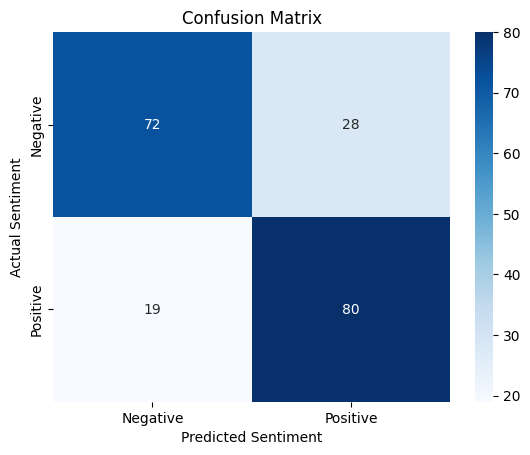

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
new_reviews = [
    "The food was delicious and the service was excellent",
    "The food was cold and the service was terrible",
    "Amazing restaurant with friendly staff",
    "Very bad experience",
    "The restaurant was good"
]

# Clean the new reviews
new_reviews_clean = [clean_text(r) for r in new_reviews]

# Tokenize and pad
new_seq = tokenizer.texts_to_sequences(new_reviews_clean)

new_pad = pad_sequences(
    new_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

# Predict
scores = model.predict(new_pad, verbose=0).ravel()

for review, score in zip(new_reviews, scores):
    sentiment = "Positive" if score >= 0.5 else "Negative"

    print("\nReview:", review)
    print("Predicted sentiment:", sentiment)
    print("Positive probability:", round(float(score), 3))


Review: The food was delicious and the service was excellent
Predicted sentiment: Positive
Positive probability: 1.0

Review: The food was cold and the service was terrible
Predicted sentiment: Negative
Positive probability: 0.0

Review: Amazing restaurant with friendly staff
Predicted sentiment: Positive
Positive probability: 1.0

Review: Very bad experience
Predicted sentiment: Negative
Positive probability: 0.016

Review: The restaurant was good
Predicted sentiment: Positive
Positive probability: 0.965
